In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load both sheets
file_path = "../data/raw/online_retail_II.xlsx"

df_2009 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

df_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011"
)

# Combine both years
df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [2]:
# 1. Check missing values
print("Missing values per column:")
display(df.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check invalid quantities and prices
print("\nQuantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())

# 4. Check cancelled invoices
cancelled = df["Invoice"].astype(str).str.startswith("C")
print("\nCancelled invoice rows:", cancelled.sum())

Missing values per column:


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


Duplicate rows: 34335

Quantity <= 0: 22950
Price <= 0: 6207

Cancelled invoice rows: 19494


In [3]:
print("Duplicate rows:", df.duplicated().sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())

cancelled = df["Invoice"].astype(str).str.startswith("C")
print("Cancelled invoice rows:", cancelled.sum())

Duplicate rows: 34335
Quantity <= 0: 22950
Price <= 0: 6207
Cancelled invoice rows: 19494


In [4]:
# Dataset date range
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

# Unique entities
print("Unique customers:", df["Customer ID"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique countries:", df["Country"].nunique())
print("Unique invoice IDs:", df["Invoice"].nunique())

# Basic revenue calculation — before cleaning
df["Revenue"] = df["Quantity"] * df["Price"]
print("Raw net line revenue:", round(df["Revenue"].sum(), 2))

First transaction: 2009-12-01 07:45:00
Last transaction: 2011-12-09 12:50:00
Unique customers: 5942
Unique products: 5305
Unique countries: 43
Unique invoice IDs: 53628
Raw net line revenue: 19287250.57


In [5]:
# Top 10 products by raw net line revenue
top_products = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 products by raw net revenue:")
display(top_products.to_frame("Revenue"))

# Top 10 countries by raw net line revenue
top_countries = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 countries by raw net revenue:")
display(top_countries.to_frame("Revenue"))

# Monthly raw net line revenue
monthly_revenue = (
    df.set_index("InvoiceDate")["Revenue"]
    .resample("MS")
    .sum()
)

print("Monthly revenue:")
display(monthly_revenue.to_frame("Revenue").head(10))

Top 10 products by raw net revenue:


,Revenue
Description,
REGENCY CAKESTAND 3 TIER,327813.65
DOTCOM POSTAGE,322647.47
WHITE HANGING HEART T-LIGHT HOLDER,257533.90
JUMBO BAG RED RETROSPOT,148800.64
PARTY BUNTING,147948.50
ASSORTED COLOUR BIRD ORNAMENT,131413.85
PAPER CHAIN KIT 50'S CHRISTMAS,121662.14
POSTAGE,112341.00
CHILLI LIGHTS,84854.16


Top 10 countries by raw net revenue:


,Revenue
Country,
United Kingdom,1.638258e+07
EIRE,6.155196e+05
Netherlands,5.485249e+05
Germany,4.179886e+05
France,3.281918e+05
Australia,1.671291e+05
Switzerland,9.972876e+04
Spain,9.185948e+04
Sweden,8.780942e+04


Monthly revenue:


,Revenue
InvoiceDate,
2009-12-01,799847.110
2010-01-01,624032.892
2010-02-01,533091.426
2010-03-01,765848.761
2010-04-01,590580.432
2010-05-01,615322.830
2010-06-01,679786.610
2010-07-01,575236.360
2010-08-01,656776.340


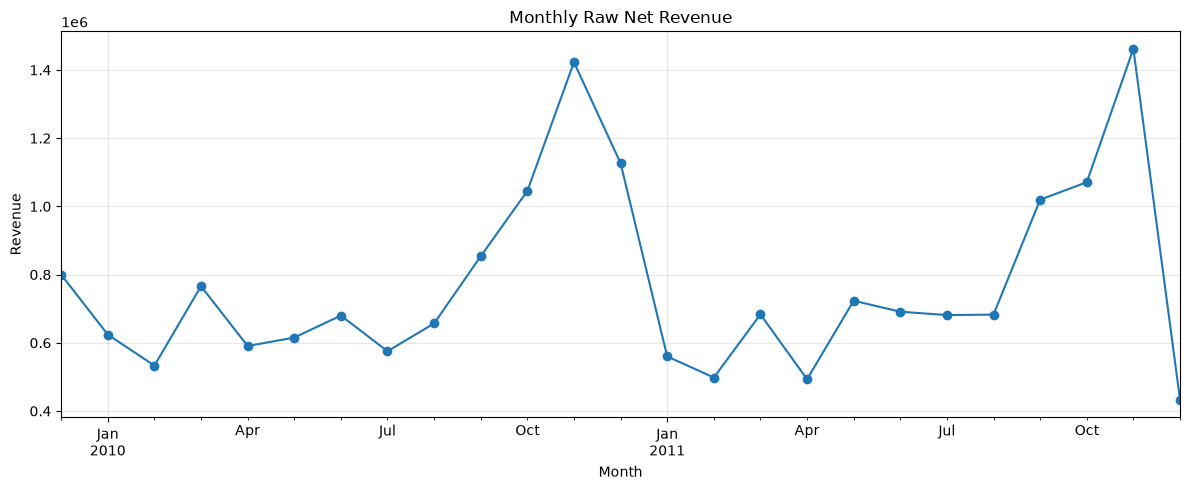

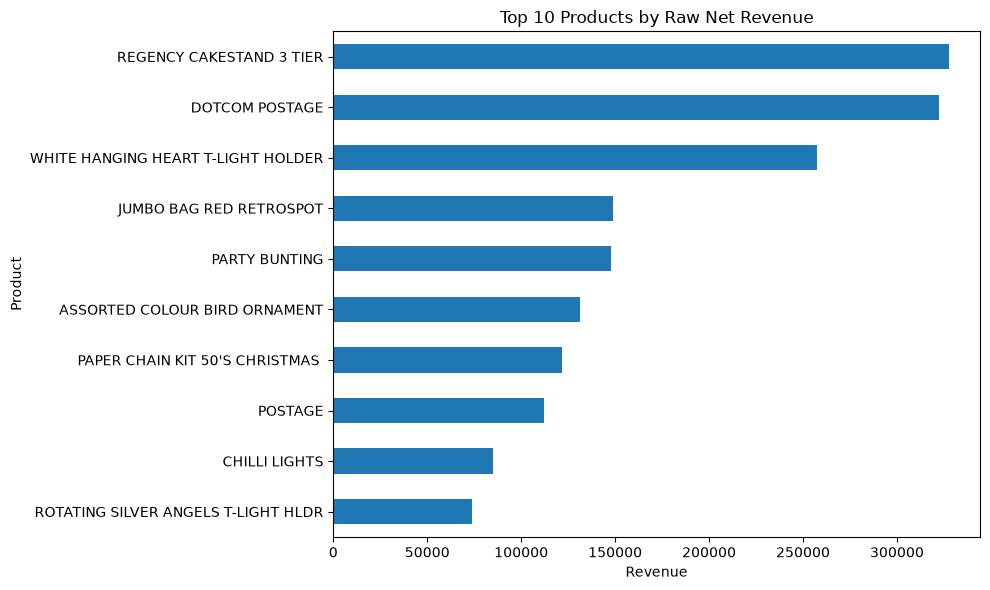

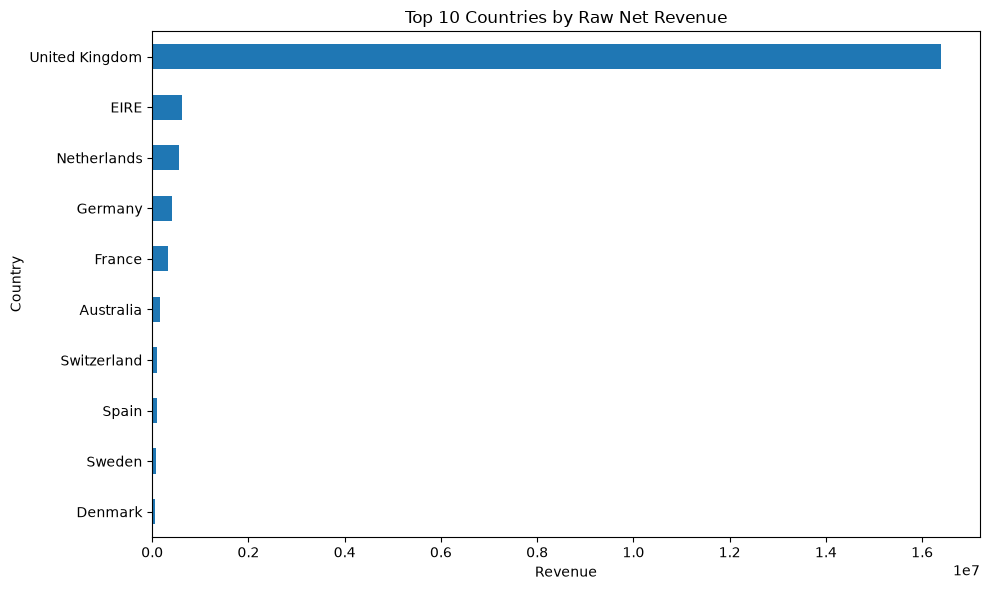

In [6]:
# 1. Monthly revenue trend
monthly_revenue.plot(figsize=(12, 5), marker="o")
plt.title("Monthly Raw Net Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Top 10 products
top_products.sort_values().plot(
    kind="barh", figsize=(10, 6)
)
plt.title("Top 10 Products by Raw Net Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# 3. Top 10 countries
top_countries.sort_values().plot(
    kind="barh", figsize=(10, 6)
)
plt.title("Top 10 Countries by Raw Net Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## Day 1 — Dataset Understanding Summary

### 1. Dataset Overview
- **Dataset:** UCI Online Retail II
- **Total records:** 1,067,371
- **Total columns:** 8
- **Date range:** 1 December 2009 – 9 December 2011
- **Unique customers with IDs:** 5,942
- **Unique products:** 5,305
- **Unique invoice IDs:** 53,628
- **Countries:** 43
- **Raw net line revenue:** £19,287,250.57

### 2. Data Quality Findings
- Missing Customer IDs: 243,007
- Missing descriptions: 4,382
- Duplicate rows: 34,335
- Non-positive quantities: 22,950
- Non-positive prices: 6,207
- Rows with cancelled invoice IDs: 19,494

These categories may overlap. The raw dataset has not been cleaned or modified.

### 3. Key Business Findings
1. The United Kingdom generates the highest raw net line revenue, approximately £16.38 million.
2. EIRE and the Netherlands rank second and third by raw net line revenue.
3. REGENCY CAKESTAND 3 TIER is the highest-ranked product by raw net line revenue.
4. Postage-related entries appear among the top revenue descriptions.
5. The dataset covers approximately two years of transactions, making it useful for studying sales trends.
6. Missing customer IDs will need special handling for customer-level analytics.
7. Returns, cancellations and duplicate records may affect raw revenue and product rankings.

### 4. Relevance to RetailPulse
- **RFM analysis:** Customer ID, InvoiceDate, Invoice, Quantity and Price.
- **Customer segmentation:** Customer-level RFM features.
- **Churn prediction:** Historical purchase activity and a carefully defined churn label.
- **Demand forecasting:** InvoiceDate, StockCode and Quantity.
- **Inventory intelligence:** Product-level sales volume over time.
- **Dashboard:** Revenue, orders, products, customers, countries and monthly trends.

### 5. Day 1 Conclusion
The dataset contains useful information for RetailPulse's customer analytics and demand forecasting features. The next stage is to inspect and clean transaction records while preserving the original raw Excel file.